# Data Collection & Exploratory Data Analysis


In [19]:
import warnings
warnings.filterwarnings('ignore')

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
from collections import Counter

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100

## Load & Basic Overview

In [21]:
DATA_PATH = '../data/raw/rawReviews.csv'
data_set = pd.read_csv(DATA_PATH)
data_set.head()

,id,source,source_language,text,rating,sentiment_given
0,0,amazon,english,No white background! It’s clear!. I bought thi...,4.0,NaN
1,1,amazon,english,Awesome! Great price! Works well!. Perfect. ...,5.0,NaN
2,2,amazon,english,Worked but took an hour to install. Overall ve...,5.0,NaN
3,3,amazon,english,Decent. Lasted about 9 months then the lock bu...,4.0,NaN
4,4,amazon,english,LOVE IT!. LOVE THIS CASE! Works better than my...,5.0,NaN


In [22]:
print(f'Rows:    {data_set.shape[0]:,}')
print(f'Columns: {data_set.shape[1]}')
print(f'Column names: {data_set.columns.tolist()}')
print()
data_set.info()

Rows:    302,640
Columns: 6
Column names: ['id', 'source', 'source_language', 'text', 'rating', 'sentiment_given']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 302640 entries, 0 to 302639
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               302640 non-null  int64  
 1   source           302640 non-null  object 
 2   source_language  302640 non-null  object 
 3   text             302636 non-null  object 
 4   rating           289869 non-null  float64
 5   sentiment_given  2766 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 13.9+ MB


## Missing Values & Duplicates

In [23]:
missing = data_set.isnull().sum().sort_values(ascending=False)

missing_pct = data_set.isnull().mean().mul(100).round(2).sort_values(ascending=False)
missing_df = pd.DataFrame({'missing_count': missing, 'missing_%': missing_pct})

print('Missing values per column:')
print(missing_df)
print()
print(f'Duplicate rows: {data_set.duplicated().sum():,}')

Missing values per column:
                 missing_count  missing_%
id                           0       0.00
rating                   12771       4.22
sentiment_given         299874      99.09
source                       0       0.00
source_language              0       0.00
text                         4       0.00

Duplicate rows: 0


In [24]:
# Fill the 4 null text rows with the most frequent text value
data_set['text'] = data_set['text'].fillna(data_set['text'].mode()[0])
print(f'Null text rows after fill: {data_set["text"].isnull().sum()}')

Null text rows after fill: 0


##  Rating Distribution

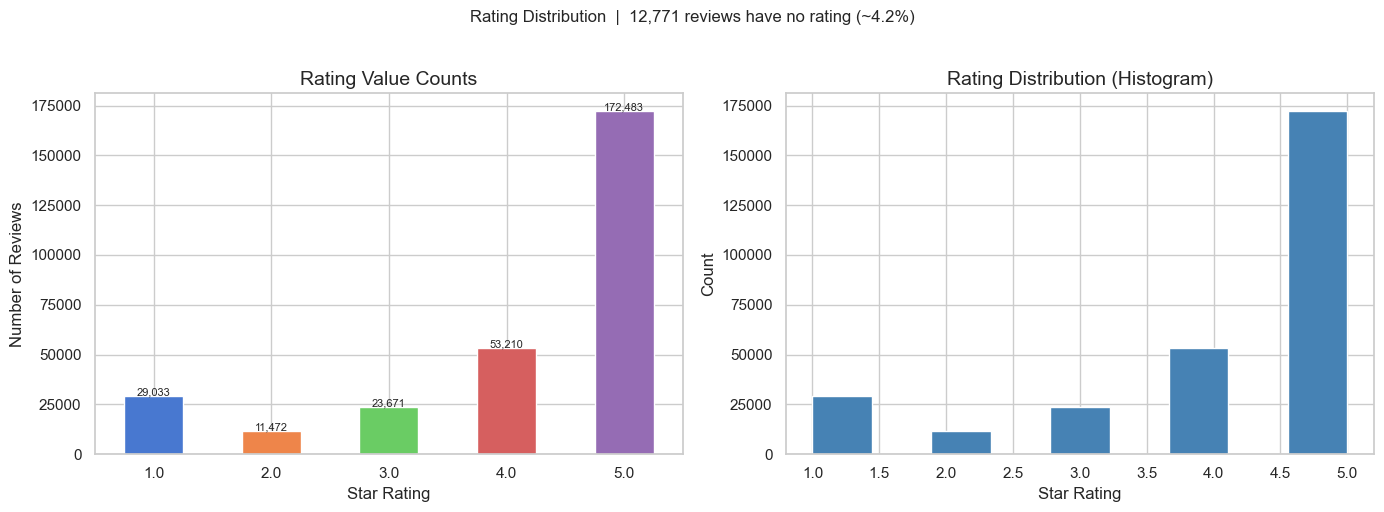

Rating statistics:
count    289869.000000
mean          4.133747
std           1.310936
min           1.000000
25%           4.000000
50%           5.000000
75%           5.000000
max           5.000000
Name: rating, dtype: float64


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rating_counts = data_set['rating'].value_counts().sort_index()
colors = sns.color_palette('muted', len(rating_counts))

rating_counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='white')
axes[0].set_title('Rating Value Counts', fontsize=14)
axes[0].set_xlabel('Star Rating')
axes[0].set_ylabel('Number of Reviews')
axes[0].tick_params(axis='x', rotation=0)
for i, v in enumerate(rating_counts):
    axes[0].text(i, v + 300, f'{v:,}', ha='center', fontsize=8)

data_set['rating'].dropna().plot(
    kind='hist', bins=9, ax=axes[1], color='steelblue', edgecolor='white')
axes[1].set_title('Rating Distribution (Histogram)', fontsize=14)
axes[1].set_xlabel('Star Rating')
axes[1].set_ylabel('Count')

plt.suptitle('Rating Distribution  |  12,771 reviews have no rating (~4.2%)', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

print('Rating statistics:')
print(data_set['rating'].describe())

##  Source Platform Distribution

Reviews per platform:
source
flipkart            189874
amazon              100000
hinglish_youtube     10000
hinglish_kaggle       2766


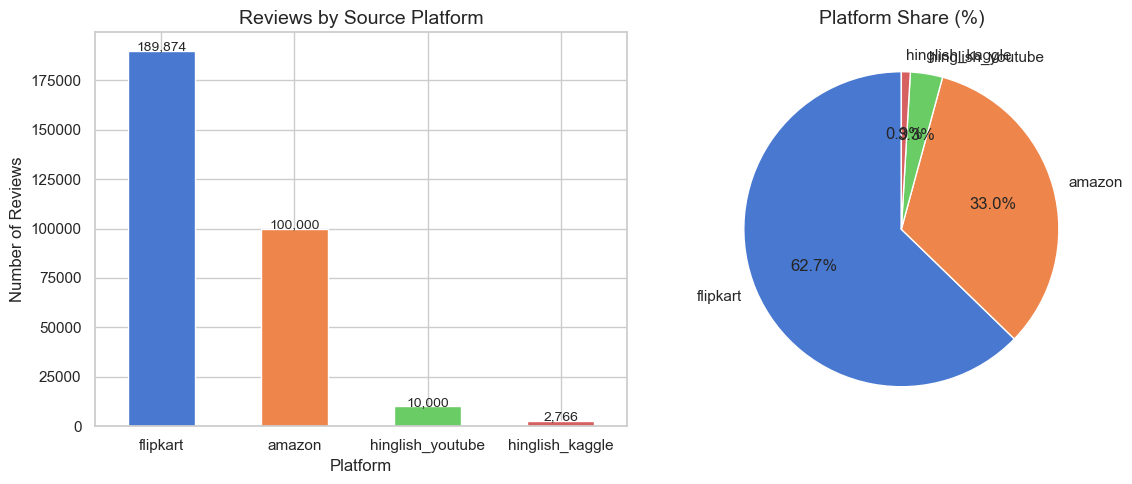

In [26]:
source_counts = data_set['source'].value_counts()
print('Reviews per platform:')
print(source_counts.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = sns.color_palette('muted', len(source_counts))

source_counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='white')
axes[0].set_title('Reviews by Source Platform', fontsize=14)
axes[0].set_xlabel('Platform')
axes[0].set_ylabel('Number of Reviews')
axes[0].tick_params(axis='x', rotation=0)
for i, v in enumerate(source_counts):
    axes[0].text(i, v + 300, f'{v:,}', ha='center', fontsize=10)

source_counts.plot(
    kind='pie', ax=axes[1], autopct='%1.1f%%', colors=colors, startangle=90)
axes[1].set_title('Platform Share (%)', fontsize=14)
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

## Language Mix

Language distribution:
source_language
mostly_english_some_hinglish    189874
english                         100000
hinglish                         12766

Percentages:
source_language
mostly_english_some_hinglish    62.74
english                         33.04
hinglish                         4.22


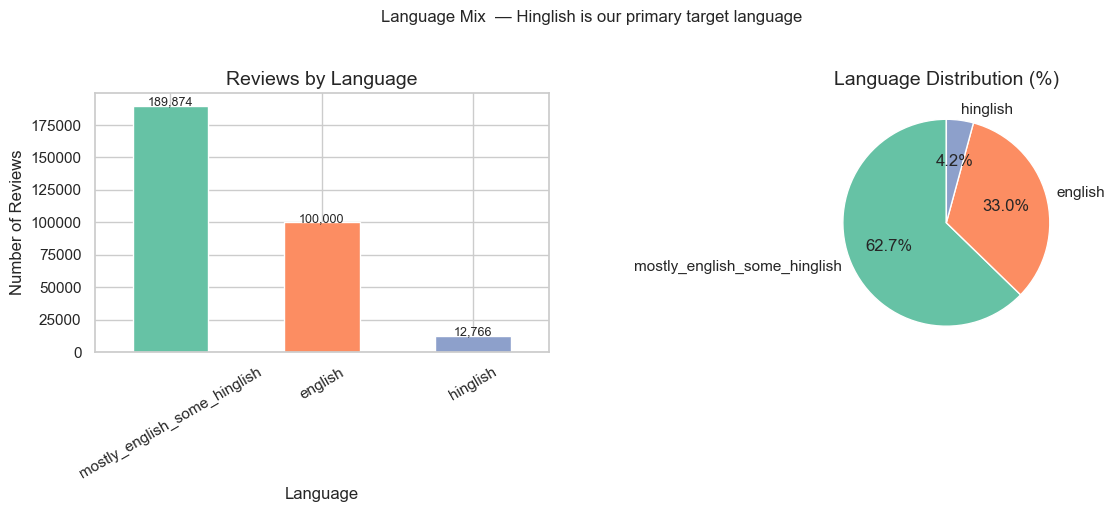

In [27]:
lang_counts = data_set['source_language'].value_counts()
print('Language distribution:')
print(lang_counts.to_string())
print()
print('Percentages:')
print((lang_counts / len(data_set) * 100).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = sns.color_palette('Set2', len(lang_counts))

lang_counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='white')
axes[0].set_title('Reviews by Language', fontsize=14)
axes[0].set_xlabel('Language')
axes[0].set_ylabel('Number of Reviews')
axes[0].tick_params(axis='x', rotation=30)
for i, v in enumerate(lang_counts):
    axes[0].text(i, v + 300, f'{v:,}', ha='center', fontsize=9)

lang_counts.plot(
    kind='pie', ax=axes[1], autopct='%1.1f%%', colors=colors, startangle=90)
axes[1].set_title('Language Distribution (%)', fontsize=14)
axes[1].set_ylabel('')

plt.suptitle('Language Mix  — Hinglish is our primary target language', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

##  Data Cleaning

In [28]:
data_set = data_set.drop(columns=['rating'])
print(f'Columns after drop: {data_set.columns.tolist()}')
print(f'Shape: {data_set.shape}')

Columns after drop: ['id', 'source', 'source_language', 'text', 'sentiment_given']
Shape: (302640, 5)


## Review Length Distribution

Character Count Statistics:
count    302640.0
mean         97.3
std         243.3
min           2.0
25%           9.0
50%          17.0
75%          81.0
max       10712.0
Name: char_count, dtype: float64

Word Count Statistics:
count    302640.0
mean         17.9
std          44.9
min           1.0
25%           1.0
50%           2.0
75%          15.0
max        1818.0
Name: word_count, dtype: float64


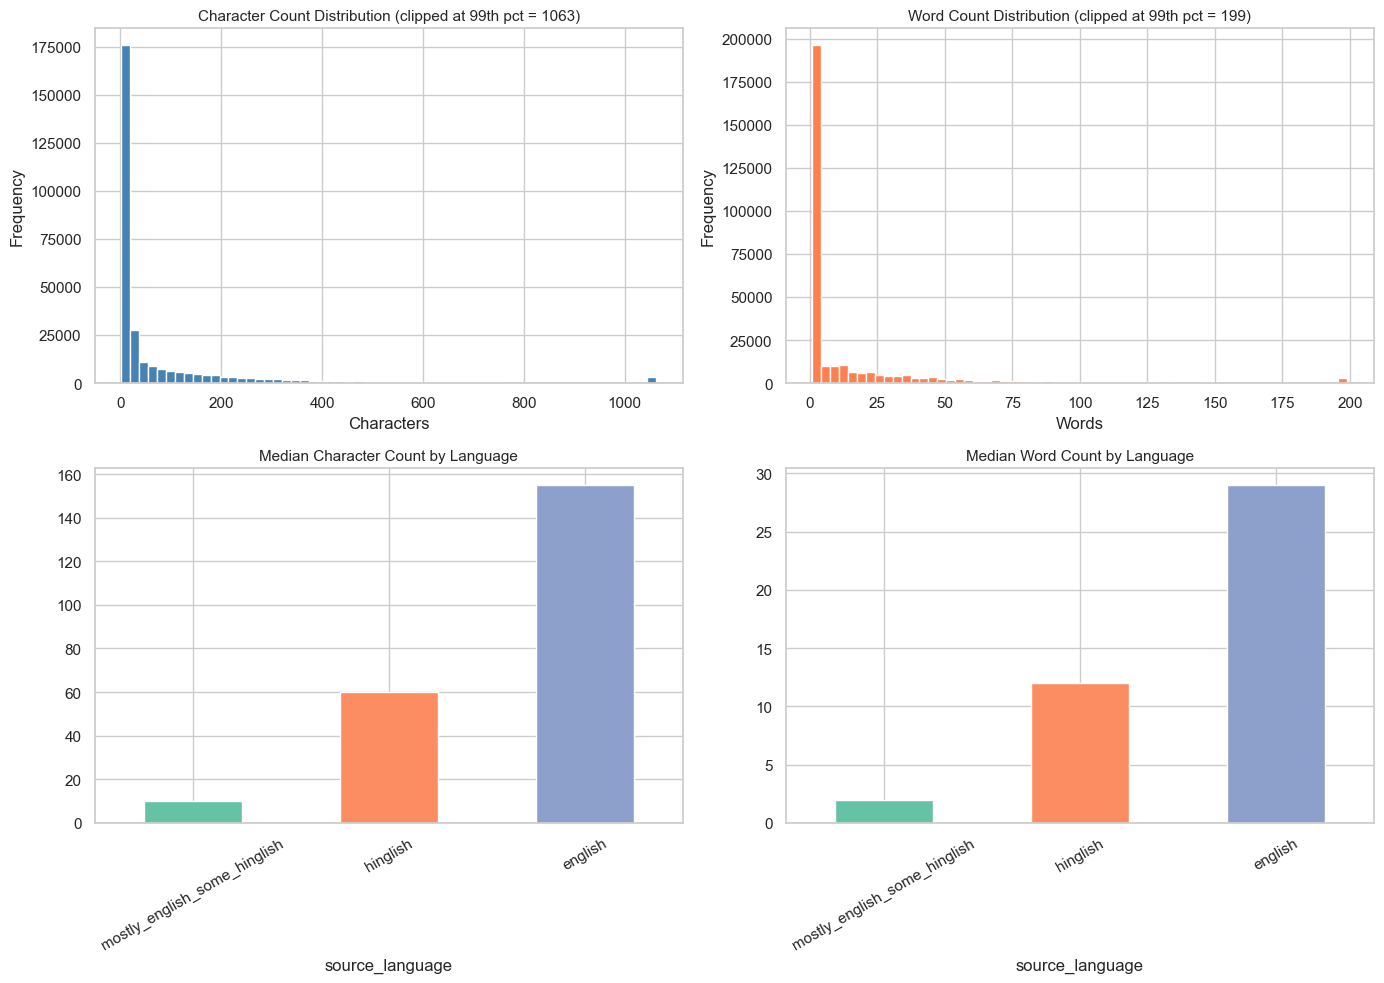

In [29]:
data_set['char_count'] = data_set['text'].str.len()
data_set['word_count'] = data_set['text'].str.split().str.len()

print('Character Count Statistics:')
print(data_set['char_count'].describe().round(1))
print()
print('Word Count Statistics:')
print(data_set['word_count'].describe().round(1))

p99_char = data_set['char_count'].quantile(0.99)
p99_word = data_set['word_count'].quantile(0.99)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Overall char distribution 
data_set['char_count'].clip(upper=p99_char).plot(
    kind='hist', bins=60, ax=axes[0][0], color='steelblue', edgecolor='white')
axes[0][0].set_title(f'Character Count Distribution (clipped at 99th pct = {p99_char:.0f})', fontsize=11)
axes[0][0].set_xlabel('Characters')

# Overall word distribution
data_set['word_count'].clip(upper=p99_word).plot(
    kind='hist', bins=60, ax=axes[0][1], color='coral', edgecolor='white')
axes[0][1].set_title(f'Word Count Distribution (clipped at 99th pct = {p99_word:.0f})', fontsize=11)
axes[0][1].set_xlabel('Words')

# Median char count by language
data_set.groupby('source_language')['char_count'].median().sort_values().plot(
    kind='bar', ax=axes[1][0],
    color=sns.color_palette('Set2', data_set['source_language'].nunique()), edgecolor='white')
axes[1][0].set_title('Median Character Count by Language', fontsize=11)
axes[1][0].tick_params(axis='x', rotation=30)

# Median word count by language
data_set.groupby('source_language')['word_count'].median().sort_values().plot(
    kind='bar', ax=axes[1][1],
    color=sns.color_palette('Set2', data_set['source_language'].nunique()), edgecolor='white')
axes[1][1].set_title('Median Word Count by Language', fontsize=11)
axes[1][1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## Sentiment Label Distribution (`sentiment_given`)

Total reviews:    302,640
Labeled reviews:  2,766 (0.91%)
Unlabeled:        299,874 (99.09%)

Sentiment class breakdown (labeled subset):
sentiment_given
neutral     1234
positive     987
negative     545
Name: count, dtype: int64


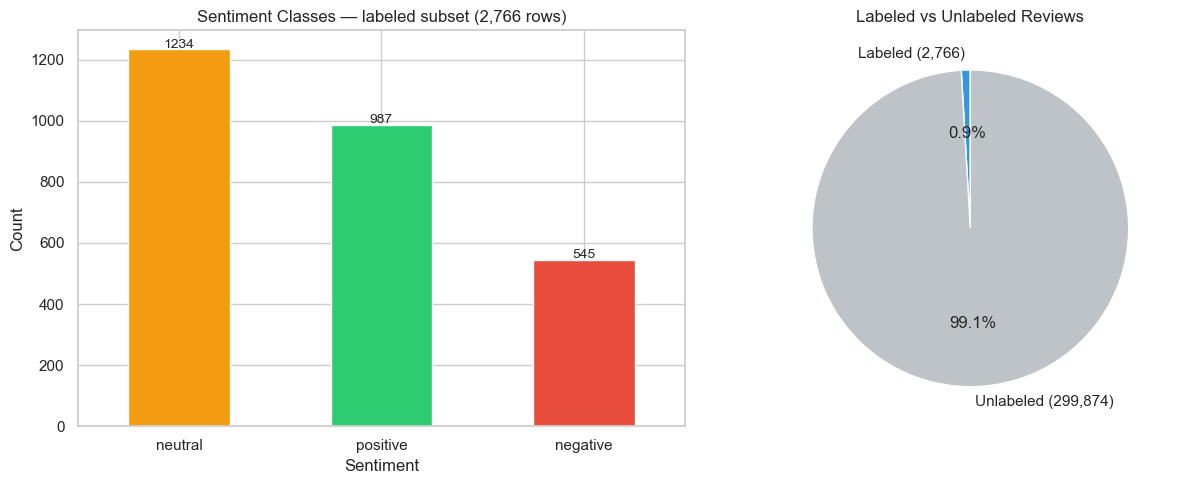


  99%+ of reviews have no label.
   → Aspect labels must be created from scratch using lexicon-based weak supervision.
   → A hand-labeled gold test set (~500 reviews) will be our trustworthy evaluation benchmark.


In [30]:
labeled = data_set[data_set['sentiment_given'].notna()].copy()

print(f'Total reviews:    {len(data_set):,}')
print(f'Labeled reviews:  {len(labeled):,} ({len(labeled)/len(data_set)*100:.2f}%)')
print(f'Unlabeled:        {len(data_set) - len(labeled):,} ({(1 - len(labeled)/len(data_set))*100:.2f}%)')
print()
print('Sentiment class breakdown (labeled subset):')
print(labeled['sentiment_given'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
counts = labeled['sentiment_given'].value_counts()
palette = {'positive': '#2ecc71', 'negative': '#e74c3c', 'neutral': '#f39c12', 'mixed': '#3498db'}
colors = [palette.get(str(k).lower(), '#95a5a6') for k in counts.index]

counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='white')
axes[0].set_title(f'Sentiment Classes — labeled subset ({len(labeled):,} rows)', fontsize=12)
axes[0].set_xlabel('Sentiment')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)
for i, v in enumerate(counts):
    axes[0].text(i, v + 5, str(v), ha='center', fontsize=10)

overall = pd.Series({
    f'Labeled ({len(labeled):,})': len(labeled),
    f'Unlabeled ({len(data_set)-len(labeled):,})': len(data_set) - len(labeled)
})
overall.plot(kind='pie', ax=axes[1], autopct='%1.1f%%',
             colors=['#3498db', '#bdc3c7'], startangle=90)
axes[1].set_title('Labeled vs Unlabeled Reviews', fontsize=12)
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

print('\n  99%+ of reviews have no label.')
print('   → Aspect labels must be created from scratch using lexicon-based weak supervision.')
print('   → A hand-labeled gold test set (~500 reviews) will be our trustworthy evaluation benchmark.')


## Sample Reviews by Language

In [31]:
print('Unique source_language values:', data_set['source_language'].unique().tolist())
print()

for lang in data_set['source_language'].unique():
    subset = data_set[data_set['source_language'] == lang]
    print('=' * 80)
    print(f'  LANGUAGE: {lang.upper()}  |  {len(subset):,} reviews')
    print('=' * 80)
    samples = subset['text'].sample(min(5, len(subset)), random_state=42).values
    for i, text in enumerate(samples, 1):
        preview = str(text)[:280]
        suffix = '...' if len(str(text)) > 280 else ''
        print(f'  [{i}] {preview}{suffix}')
        print()
    print()

Unique source_language values: ['english', 'mostly_english_some_hinglish', 'hinglish']

  LANGUAGE: ENGLISH  |  100,000 reviews
  [1] Durable but slippery. It’s a bit slippery. However it seems to protect the phone well.

  [2] my husband uses this and its a really nice case and slim for ease in and out of .... my husband uses this and its a really nice case and slim for ease in and out of pockets.

  [3] Waste of Money!. Poor quality. After applying it to my sons Gizmo watch it left tons of white residue and bubbles hat could not be pressed out. I’ve installed a million protectors similar to this and have never seen such poor quality. It irritated my son and I so such we just rem...

  [4] oops. I bought the wrong one, and lost the paper work to send back, my bad.  The camera space doesn't fit my phone...

  [5] Well made. Really well put together and works well in the gym.


  LANGUAGE: MOSTLY_ENGLISH_SOME_HINGLISH  |  189,874 reviews
  [1] Terrific

  [2] Super!

  [3] Must buy!

  


## Aspect Keyword Coverage

Aspect keyword coverage in raw data:
           review_count  percentage
price             31894       10.54
quality           18316        6.05
battery           14500        4.79
packaging          6668        2.20
service            6424        2.12
delivery           4610        1.52


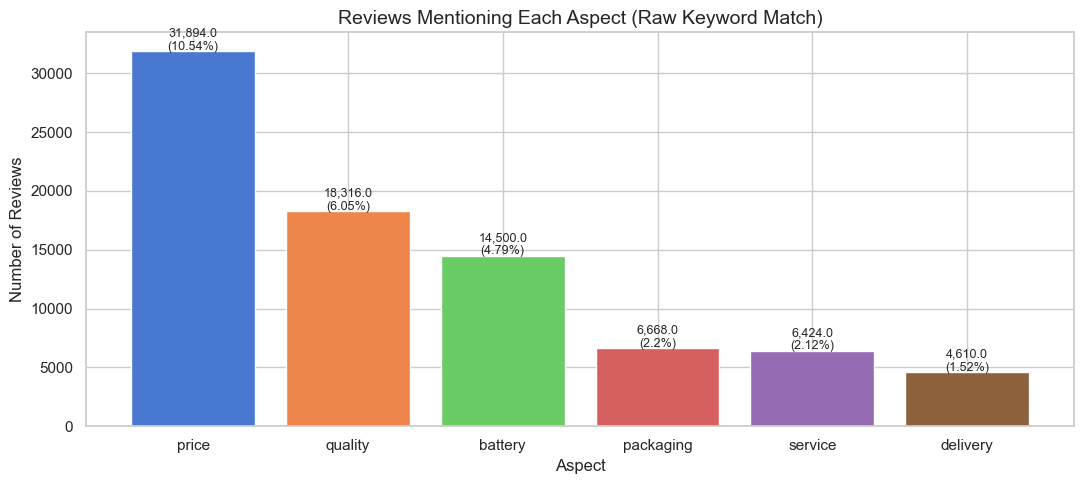

In [32]:
ASPECT_KEYWORDS = {
    'battery':   ['battery', 'charging', 'backup', 'charge', 'drain', 'charger', 'mah'],
    'delivery':  ['delivery', 'courier', 'shipping', 'dispatch', 'late', 'delay', 'arrived', 'shipped'],
    'price':     ['price', 'cost', 'expensive', 'cheap', 'worth', 'value', 'paisa', 'mehenga', 'affordable'],
    'quality':   ['quality', 'material', 'durability', 'build', 'performance', 'kharab', 'ghatiya', 'durable'],
    'packaging': ['packaging', 'package', 'box', 'damaged', 'broken', 'seal', 'dabba', 'bubble wrap'],
    'service':   ['support', 'warranty', 'customer care', 'refund', 'service', 'replacement', 'return'],
}

text_lower = data_set['text'].str.lower()

aspect_counts = {}
for aspect, keywords in ASPECT_KEYWORDS.items():
    pattern = '|'.join(re.escape(k) for k in keywords)
    count = text_lower.str.contains(pattern, regex=True).sum()
    aspect_counts[aspect] = count

aspect_df = pd.DataFrame.from_dict(
    aspect_counts, orient='index', columns=['review_count'])
aspect_df['percentage'] = (aspect_df['review_count'] / len(data_set) * 100).round(2)
aspect_df = aspect_df.sort_values('review_count', ascending=False)

print('Aspect keyword coverage in raw data:')
print(aspect_df.to_string())

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(
    aspect_df.index, aspect_df['review_count'],
    color=sns.color_palette('muted', len(aspect_df)), edgecolor='white')
ax.set_title('Reviews Mentioning Each Aspect (Raw Keyword Match)', fontsize=14)
ax.set_xlabel('Aspect')
ax.set_ylabel('Number of Reviews')
for bar, (idx, row) in zip(bars, aspect_df.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() + 100,
        f'{row["review_count"]:,}\n({row["percentage"]}%)',
        ha='center', fontsize=9)
plt.tight_layout()
plt.show()

In [33]:
# Multi-aspect co-occurrence: how many reviews mention 2+ aspects?
for aspect, keywords in ASPECT_KEYWORDS.items():
    pattern = '|'.join(re.escape(k) for k in keywords)
    data_set[f'has_{aspect}'] = text_lower.str.contains(pattern, regex=True).astype(int)

aspect_flag_cols = [f'has_{a}' for a in ASPECT_KEYWORDS]
data_set['aspect_count'] = data_set[aspect_flag_cols].sum(axis=1)

print('Aspect count distribution per review:')
print(data_set['aspect_count'].value_counts().sort_index())
multi = (data_set['aspect_count'] >= 2).sum()
print(f'\nMulti-aspect reviews (2+ aspects): {multi:,} ({multi/len(data_set)*100:.2f}%)')
print('→ Multi-label classification is the right framing (not multi-class).')

Aspect count distribution per review:
aspect_count
0    237853
1     51167
2     10370
3      2627
4       500
5       114
6         9
Name: count, dtype: int64

Multi-aspect reviews (2+ aspects): 13,620 (4.50%)
→ Multi-label classification is the right framing (not multi-class).


## Top Frequent Words

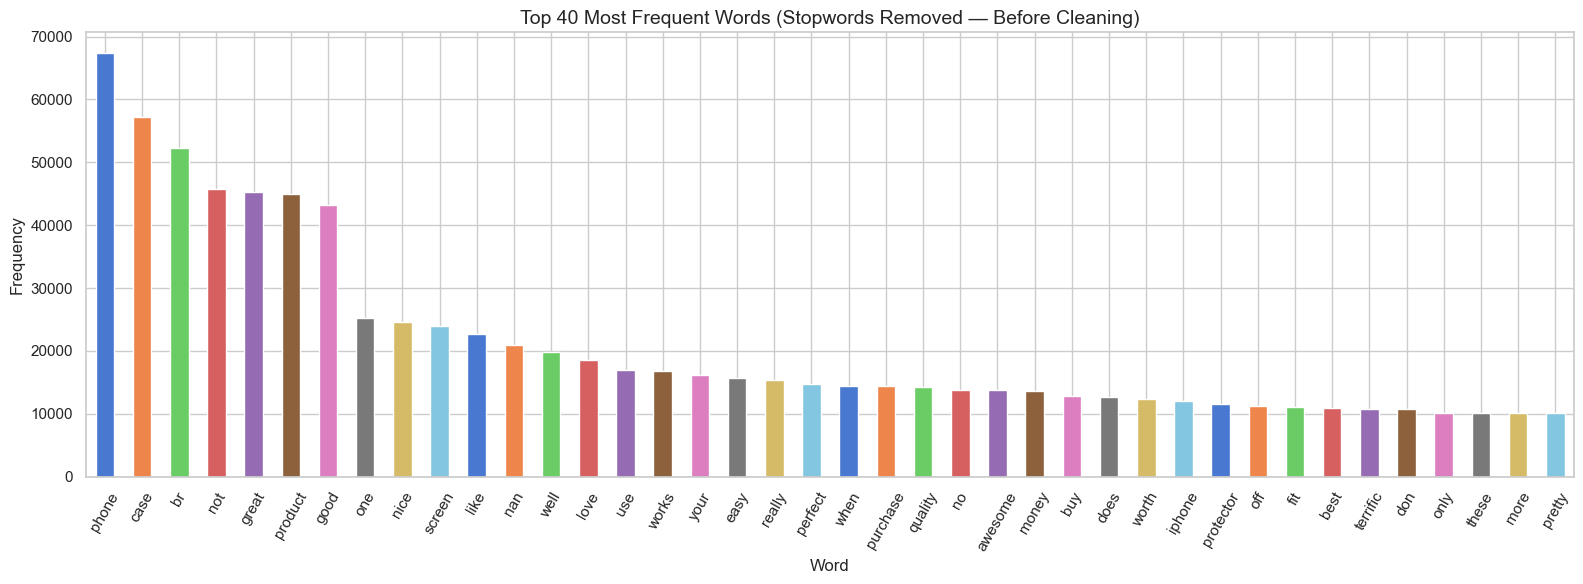

Top 20 words:
  phone                    67,319
  case                     57,288
  br                       52,236
  not                      45,713
  great                    45,293
  product                  45,011
  good                     43,212
  one                      25,183
  nice                     24,577
  screen                   23,920
  like                     22,700
  nan                      20,866
  well                     19,887
  love                     18,590
  use                      17,002
  works                    16,768
  your                     16,086
  easy                     15,610
  really                   15,392
  perfect                  14,716


In [34]:
# Join all text, lowercase, strip non-alpha characters
all_text = ' '.join(data_set['text'].dropna().astype(str)).lower()
all_text = re.sub(r'[^a-z\s]', ' ', all_text)
word_freq = Counter(all_text.split())

# Stopwords removed ONLY for this visualization — not for features
VIZ_STOPWORDS = {
    'the', 'a', 'and', 'is', 'it', 'in', 'of', 'to', 'i', 'this', 'was', 'for',
    'with', 'my', 'are', 'but', 'have', 'be', 'at', 'on', 'as', 'an', 'its', 'so',
    'very', 'too', 'that', 'has', 'they', 'from', 'or', 'by', 'you', 'am', 'we',
    'do', 'if', 'me', 'he', 'she', 'up', 'out', 'just', 'than', 'then', 'been',
    'also', 'had', 'can', 'all', 'will', 'would', 'their', 'it', 'get'
}
filtered = {w: c for w, c in word_freq.items()
            if w not in VIZ_STOPWORDS and len(w) > 1}
top_40 = pd.Series(filtered).nlargest(40)

fig, ax = plt.subplots(figsize=(16, 6))
top_40.plot(kind='bar', ax=ax,
            color=sns.color_palette('muted', 40), edgecolor='white')
ax.set_title('Top 40 Most Frequent Words (Stopwords Removed — Before Cleaning)', fontsize=14)
ax.set_xlabel('Word')
ax.set_ylabel('Frequency')
ax.tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()

print('Top 20 words:')
for word, count in top_40.head(20).items():
    print(f'  {word:<20} {count:>10,}')


## Data Quality Checks


In [35]:
print('=== DATA QUALITY CHECKS ===\n')

# Very short reviews (< 10 chars)
short = data_set[data_set['char_count'] < 10]
print(f'Very short reviews (< 10 chars):       {len(short):,}')
if len(short) > 0:
    print('  Examples:', short['text'].head(5).tolist())

# Junk reviews (only digits/punctuation)
junk_pattern = r'^[\d\s\.\!\?\,\-\'"]+$'
junk = data_set[data_set['text'].str.match(junk_pattern, na=False)]
print(f'\nJunk reviews (only digits/punct):      {len(junk):,}')
if len(junk) > 0:
    print('  Examples:', junk['text'].head(5).tolist())

# Reviews containing URLs
url_reviews = data_set[data_set['text'].str.contains(r'https?://', na=False)]
print(f'\nReviews containing URLs:               {len(url_reviews):,}')

# Very long reviews
p99_char = data_set['char_count'].quantile(0.99)
long_reviews = data_set[data_set['char_count'] > p99_char]
print(f'\nVery long reviews (> 99th pct = {p99_char:.0f}): {len(long_reviews):,}')

# Reviews with emojis
emoji_re = re.compile(
    '[\U00010000-\U0010ffff\U00002600-\U000027BF]+', flags=re.UNICODE)
has_emoji = data_set[data_set['text'].apply(
    lambda x: bool(emoji_re.search(str(x))))]
print(f'\nReviews containing emojis:             {len(has_emoji):,}')
print('  (Emojis carry sentiment — they will be mapped to words in preprocessing)')

print(f'\n✅ Summary:')
print(f'   Total rows:           {len(data_set):,}')
print(f'   Usable (>= 10 chars): {len(data_set[data_set["char_count"] >= 10]):,}')
print(f'   Flagged for cleanup:  {len(short) + len(junk):,}')

=== DATA QUALITY CHECKS ===

Very short reviews (< 10 chars):       92,137
  Examples: [':p. :p', '👍. 👍', '👍. 👍', '👍. 👍', '👍. 👍']

Junk reviews (only digits/punct):      3
  Examples: ['-. -', '9838797786', '50 - 50']

Reviews containing URLs:               45

Very long reviews (> 99th pct = 1063): 3,023

Reviews containing emojis:             1,277
  (Emojis carry sentiment — they will be mapped to words in preprocessing)

✅ Summary:
   Total rows:           302,640
   Usable (>= 10 chars): 210,503
   Flagged for cleanup:  92,140



## Save Cleaned Baseline


In [36]:
# Drop EDA helper columns before saving
helper_cols = (['char_count', 'word_count', 'aspect_count']
               + [f'has_{a}' for a in ASPECT_KEYWORDS])
save_df = data_set.drop(
    columns=[c for c in helper_cols if c in data_set.columns])

os.makedirs('../data/processed', exist_ok=True)
out_path = '../data/processed/reviews_cleaned.csv'
save_df.to_csv(out_path, index=False)

print(f'Saved to : {out_path}')
print(f'Rows     : {len(save_df):,}')
print(f'Columns  : {save_df.columns.tolist()}')
print()
save_df.head(3)

Saved to : ../data/processed/reviews_cleaned.csv
Rows     : 302,640
Columns  : ['id', 'source', 'source_language', 'text', 'sentiment_given']



,id,source,source_language,text,sentiment_given
0,0,amazon,english,No white background! It’s clear!. I bought thi...,NaN
1,1,amazon,english,Awesome! Great price! Works well!. Perfect. ...,NaN
2,2,amazon,english,Worked but took an hour to install. Overall ve...,NaN


---
## 📋 EDA Summary & Key Findings

| Finding | Implication for the Project |
|:--|:--|
| 302,640 reviews — large enough for classical ML | No need to augment data initially |
| `sentiment_given` is 99%+ empty | Must create aspect labels from scratch (weak supervision + gold set) |
| `rating` is an overall star score | Dropped — cannot be used as aspect-level label proxy |
| Hinglish reviews present in the data | Justifies character n-gram features + Hinglish normalizer |
| Emojis and URLs present in text | Must be handled in preprocessing (notebook 02) |
| All 6 aspects have detectable keyword coverage | Dataset is viable for aspect detection |
| Many reviews mention 2+ aspects | Confirms **multi-label classification** (not multi-class) is the right framing |

---
**→ Next: `02_preprocessing_pipeline.ipynb`** — Hinglish normalizer, negation handling, emoji mapping, clause splitting